# 02 · Train: baseline vs fine-tuned ResNet-18 (196 car models)

In [2]:
import os, sys
REPO_URL = "https://github.com/YUPWE/car-models.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/car-models"
    if not os.path.exists(ROOT):
        !git clone {REPO_URL} {ROOT}
    os.chdir(ROOT)
    !git pull -q
    !pip install -q imagehash==4.3.2
    os.environ["CARS_DATA_DIR"] = "/content/cars_data"
else:
    ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.makedirs("results", exist_ok=True)
os.makedirs("weights", exist_ok=True)
QUICK = os.environ.get("QUICK", "0") == "1"
print("Working in", os.getcwd(), "| QUICK =", QUICK)

Mounted at /content/drive
Working in /content/drive/MyDrive/car-models | QUICK = False


In [3]:
import json, numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src import data
from src.data import CarDataset, get_transforms
from src.model import build_resnet18, train, set_seed, get_device
import torchvision, transformers, sklearn, pandas, matplotlib, PIL

data.download()
device = get_device()
print("device:", device)
for m in [torch, torchvision, transformers, sklearn, pandas, matplotlib, PIL]: print(f"  {m.__name__}=={m.__version__}")

train_df, val_df = data.load_split("train"), data.load_split("val")
if QUICK:
    train_df, val_df = train_df.sample(128, random_state=0), val_df.sample(64, random_state=0)
train_loader = DataLoader(CarDataset(train_df, get_transforms(True)), batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(CarDataset(val_df, get_transforms(False)), batch_size=128, num_workers=2)
print(len(train_df), "train /", len(val_df), "val images")

Unzipping cached images ...
device: cuda
  torch==2.14.1+cu130
  torchvision==0.29.1+cu130
  transformers==5.22.1
  sklearn==1.6.1
  pandas==2.2.3
  matplotlib==3.10.0
  PIL==11.3.0
11470 train / 2293 val images


In [4]:
EPOCHS = 1 if QUICK else 10

set_seed(42)
baseline = build_resnet18(freeze_backbone=True, num_classes=196)
baseline, hist_base = train(baseline, train_loader, val_loader, epochs=EPOCHS, lr=1e-3, device=device)
torch.save(baseline.state_dict(), "weights/resnet18_frozen.pt")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


epoch  1/10 | train loss 4.854 acc 0.062 | val loss 4.208 acc 0.157 F1 0.128 | 89s
epoch  2/10 | train loss 3.790 acc 0.220 | val loss 3.627 acc 0.239 F1 0.221 | 72s
epoch  3/10 | train loss 3.224 acc 0.332 | val loss 3.274 acc 0.290 F1 0.263 | 67s
epoch  4/10 | train loss 2.880 acc 0.389 | val loss 3.098 acc 0.319 F1 0.295 | 68s
epoch  5/10 | train loss 2.639 acc 0.439 | val loss 2.940 acc 0.369 F1 0.348 | 69s
epoch  6/10 | train loss 2.467 acc 0.480 | val loss 2.857 acc 0.366 F1 0.352 | 68s
epoch  7/10 | train loss 2.361 acc 0.503 | val loss 2.792 acc 0.386 F1 0.372 | 67s
epoch  8/10 | train loss 2.271 acc 0.528 | val loss 2.754 acc 0.382 F1 0.369 | 68s
epoch  9/10 | train loss 2.223 acc 0.544 | val loss 2.726 acc 0.392 F1 0.378 | 69s
epoch 10/10 | train loss 2.196 acc 0.555 | val loss 2.717 acc 0.394 F1 0.380 | 67s
Best validation macro-F1: 0.380


In [5]:
set_seed(42)
finetuned = build_resnet18(freeze_backbone=False, num_classes=196)
finetuned, hist_ft = train(finetuned, train_loader, val_loader, epochs=EPOCHS, lr=5e-4, device=device)
torch.save(finetuned.state_dict(), "weights/resnet18_finetuned.pt")

epoch  1/10 | train loss 3.505 acc 0.262 | val loss 2.317 acc 0.463 F1 0.444 | 72s
epoch  2/10 | train loss 1.428 acc 0.660 | val loss 1.466 acc 0.615 F1 0.606 | 73s
epoch  3/10 | train loss 0.779 acc 0.808 | val loss 1.097 acc 0.686 F1 0.680 | 72s
epoch  4/10 | train loss 0.481 acc 0.881 | val loss 0.882 acc 0.756 F1 0.751 | 72s
epoch  5/10 | train loss 0.302 acc 0.927 | val loss 0.698 acc 0.814 F1 0.811 | 70s
epoch  6/10 | train loss 0.190 acc 0.957 | val loss 0.551 acc 0.840 F1 0.836 | 72s
epoch  7/10 | train loss 0.120 acc 0.974 | val loss 0.511 acc 0.860 F1 0.856 | 72s
epoch  8/10 | train loss 0.085 acc 0.983 | val loss 0.464 acc 0.869 F1 0.867 | 72s
epoch  9/10 | train loss 0.064 acc 0.990 | val loss 0.443 acc 0.874 F1 0.873 | 72s
epoch 10/10 | train loss 0.053 acc 0.993 | val loss 0.437 acc 0.872 F1 0.870 | 71s
Best validation macro-F1: 0.873


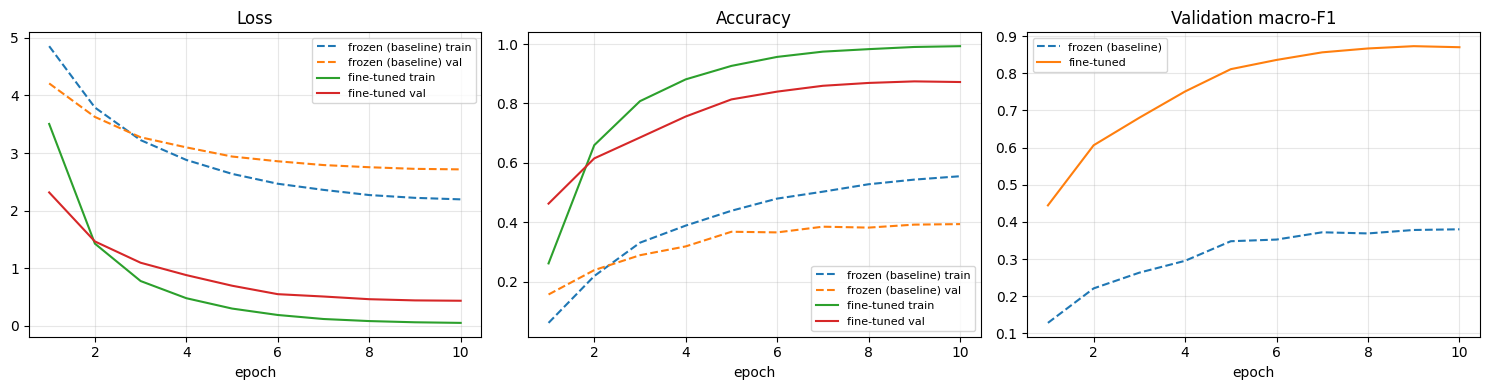

baseline (frozen)  best val macro-F1 0.380 | best val acc 0.394
fine-tuned         best val macro-F1 0.873 | best val acc 0.874


In [6]:
json.dump({"baseline_frozen": hist_base, "finetuned": hist_ft}, open("results/history.json", "w"), indent=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, h, style in [("frozen (baseline)", hist_base, "--"), ("fine-tuned", hist_ft, "-")]:
    ep = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], style, label=f"{name} train"); axes[0].plot(ep, h["val_loss"], style, label=f"{name} val")
    axes[1].plot(ep, h["train_acc"], style, label=f"{name} train"); axes[1].plot(ep, h["val_acc"], style, label=f"{name} val")
    axes[2].plot(ep, h["val_f1"], style, label=name)
for ax, t in zip(axes, ["Loss", "Accuracy", "Validation macro-F1"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/curves.png", dpi=120); plt.show()
for name, h in [("baseline (frozen)", hist_base), ("fine-tuned", hist_ft)]:
    print(f"{name:18s} best val macro-F1 {max(h['val_f1']):.3f} | best val acc {max(h['val_acc']):.3f}")